# QMSS5074GR: Projects in Advanced Machine Learning
## Project 2: CNN & Transfer Learning for Medical Image Classification

---

### Group Information

**Group number:** 4

| Full Name | UNI |
|-----------|-----|
| Yizhang Mu | ym3178 |
| Changyang Zhu | cz3003 |

**Public GitHub repository URL:** https://github.com/ElianMu/QMSS5074_Project2_Group4

## How to Complete and Submit This Project

**Due: Monday, November 16, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_2.ipynb`.

### 1. Get started

This project runs in **Google Colab**, which gives you a free GPU for training. The project folder contains the notebook:

```
Fall2026_QMSS5074GR_Project_2/
└── Project_2.ipynb
```

The dataset is too large to include in the folder, so it is shared through Google Drive (step 3 below). There is nothing else to download.

1. Unzip the project folder. Then go to [colab.research.google.com](https://colab.research.google.com), sign in with your **Columbia (LionMail) Google account**, choose **File → Upload notebook**, and select `Project_2.ipynb`.
2. Check that a GPU is on: **Runtime → Change runtime type → T4 GPU**.
3. Add the dataset to your Google Drive (you only need to do this once):
   1. Open the [shared dataset folder](https://drive.google.com/drive/folders/18O-BnGOIw9ZiUwy17Uk_361xyfTF-qAN?usp=sharing) while signed in with your Columbia account.
   2. Right-click **`COVID-19_Radiography_Dataset.zip`** and choose **Organize → Add shortcut**.
   3. Choose **All locations → My Drive → Add**.

   ![Step 1: Right-click the zip file, then Organize, then Add shortcut](https://github.com/user-attachments/assets/6515aa71-484b-4364-ac44-2331477720e8)

   ![Step 2: Choose All locations, then My Drive, then Add](https://github.com/user-attachments/assets/0d0d8f6c-a868-49c4-9e38-54f3006af39b)

4. Run the cells in **Section 0** in order. They connect to your Drive, unzip the dataset, and prepare the data you will use for every model.

**Working in Colab:**

- Colab saves your notebook in your Google Drive, in the **Colab Notebooks** folder.
- If your session disconnects, the unzipped data and trained models are lost. Run Section 0 again to continue.
- If you run out of memory, delete models you no longer need with `del model_name` and `tf.keras.backend.clear_session()`, or use the optional save and reload cells at the end of Section 0.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Runtime → Restart session and run all**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible. Training several models takes time, so leave enough time for this final run.
- Fill in the **Group Information** cell at the top, including your GitHub link.
- Download the notebook with **File → Download → Download .ipynb**.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 2 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_2` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_2/
    └── Project_2.ipynb
```

Do **not** upload the dataset, saved data files, or saved models to GitHub. They are too large (GitHub rejects files over 100 MB).

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart session and run all finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` is in `Project_2/` in your public group repository

## About the Project

### What this project is about

Chest X-rays are one of the fastest and cheapest ways to examine the lungs, and they were widely used to screen patients during the COVID-19 pandemic. Reading them takes trained radiologists, who are often in short supply. Can a deep learning model learn to tell COVID-19, viral pneumonia, and healthy lungs apart from an X-ray image?

In this project, you will build a complete deep learning pipeline for **medical image classification**. You will train a convolutional neural network (CNN) from scratch as a baseline, apply **transfer learning** with ResNet, try three more architectures of your choice, test data augmentation, and compare every model on the same test set. Finally, you will reflect on which model works best, why, and how it could be useful in the real world.

> The models in this project are for learning purposes only. They are not suitable for diagnosing patients.

### The prediction task

This is a **multi-class image classification** problem with **three classes**:

**COVID-19 · Normal · Viral Pneumonia**

Each model takes a chest X-ray image as input and outputs the probability of each class.

### The data

The images come from the **COVID-19 Radiography Database**, created by researchers from Qatar University, the University of Dhaka, and their collaborators. It collects chest X-rays from several public sources into one dataset.

> **Citation:** M.E.H. Chowdhury, T. Rahman, A. Khandakar, R. Mazhar, M.A. Kadir, Z.B. Mahbub, K.R. Islam, M.S. Khan, A. Iqbal, N. Al-Emadi, M.B.I. Reaz, "Can AI help in screening Viral and COVID-19 pneumonia?" arXiv preprint, 29 March 2020. [https://arxiv.org/abs/2003.13145](https://arxiv.org/abs/2003.13145)

The dataset is organized into one folder per class. This project uses three of them:

| Class | Folder | Images in the dataset | Images used in this project |
|-------|--------|----------------------:|----------------------------:|
| COVID-19 | `COVID/images` | 3,616 | 1,345 |
| Normal | `Normal/images` | 10,192 | 1,345 |
| Viral Pneumonia | `Viral Pneumonia/images` | 1,345 | 1,345 |

The dataset also contains a fourth class (`Lung_Opacity`) and lung masks for each image (`masks` folders). This project does not use them.

### How the data is prepared

Section 0 prepares the data for you, so that every model uses exactly the same inputs:

- **Equal-sized classes:** A random sample of 1,345 images is taken from each class, the size of the smallest class. This keeps the data small enough for Colab's memory, and it also balances the classes. You will discuss this choice in Section 1.
- **Image format:** Each image is resized to **192 × 192** pixels, stored with **3 color channels** (so that pre-trained models such as ResNet can use it), and scaled to values between **0 and 1**.
- **Fixed split:** The data is split into **training (64%)**, **validation (16%)**, and **test (20%)** sets, with the same class proportions in each. Use these same splits for every model so that your comparisons are fair.

---

## 0. Setup and Data Loading

Run these cells in order. This code is provided, so you don't need to change it. When you finish this section, you will have `X_train`, `X_val`, `X_test` (images) and `y_train`, `y_val`, `y_test` (one-hot encoded labels).

### Connect to Google Drive

In [ ]:
# Connect to Google Drive. A pop-up will ask you to sign in: use your Columbia account.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Unzip the Dataset

In [ ]:
# Unzip the dataset into this Colab session (takes 1–2 minutes; skipped if it is already unzipped)
import os
import glob
import zipfile

drive_folder = '/content/drive/MyDrive'
zip_path = os.path.join(drive_folder, 'COVID-19_Radiography_Dataset.zip')

if not os.path.exists(zip_path):
    # Also look one folder down, in case the shortcut was added inside a folder
    matches = glob.glob(os.path.join(drive_folder, '*', 'COVID-19_Radiography_Dataset.zip'))
    if not matches:
        raise FileNotFoundError(
            "Couldn't find COVID-19_Radiography_Dataset.zip in your Google Drive. "
            "Follow step 3 of 'How to Complete and Submit This Project' to add the shortcut to My Drive.")
    zip_path = matches[0]

if not os.path.isdir('COVID-19_Radiography_Dataset'):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('.')

print('Dataset ready:', sorted(os.listdir('COVID-19_Radiography_Dataset')))

Dataset ready: ['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


### Import Libraries

In [ ]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Dense, Dropout, Flatten,
                                     BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.applications import ResNet50, VGG19, InceptionV3

# Fix random seeds so results are as repeatable as possible
keras.utils.set_random_seed(42)

print('TensorFlow version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None found. Turn it on with Runtime → Change runtime type → T4 GPU.')

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Collect Image File Paths

In [ ]:
base_path = 'COVID-19_Radiography_Dataset'
categories = ['COVID/images', 'Normal/images', 'Viral Pneumonia/images']
class_names = ['COVID', 'NORMAL', 'PNEUMONIA']

# One list of file paths per class
fnames = []
for category in categories:
    image_folder = os.path.join(base_path, category)
    file_names = sorted(os.listdir(image_folder))
    fnames.append([os.path.join(image_folder, f) for f in file_names])

# Keep the full counts: you will need them in Section 1
original_counts = dict(zip(class_names, [len(f) for f in fnames]))
print('Number of images in each class (full dataset):', original_counts)

Number of images in each class (full dataset): {'COVID': 3616, 'NORMAL': 10192, 'PNEUMONIA': 1345}


### Sample an Equal Number of Images per Class

In [ ]:
# Take a random sample from each class, the size of the smallest class.
# This keeps the data small enough for Colab's memory and balances the classes.
n_per_class = min(len(f) for f in fnames)

rng = random.Random(42)
fnames = [sorted(rng.sample(f, n_per_class)) for f in fnames]

print('Images per class used in this project:', n_per_class)

Images per class used in this project: 1345


### Preprocess the Images

In [ ]:
IMG_SIZE = 192

def preprocessor(img_path):
    """Load one image, convert it to 3-channel RGB, resize it, and scale pixel values to 0–1."""
    img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img, dtype=np.float32) / 255.0

# Try it on one image
preprocessor(fnames[0][0]).shape

(192, 192, 3)

In [ ]:
# Load and preprocess every image (takes about a minute)
image_filepaths = fnames[0] + fnames[1] + fnames[2]

X = np.empty((len(image_filepaths), IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
for i, path in enumerate(image_filepaths):
    X[i] = preprocessor(path)

print('X shape:', X.shape)          # (number of images, height, width, channels)
print('Pixel range:', X.min(), 'to', X.max())

X shape: (4035, 192, 192, 3)
Pixel range: 0.0 to 1.0


### Create the Labels

In [ ]:
# The images were loaded class by class, so the labels follow the same order
y_labels = np.repeat(class_names, n_per_class)

# One-hot encode the labels for Keras (one column per class)
y = pd.get_dummies(y_labels).astype('float32')
y

,COVID,NORMAL,PNEUMONIA
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
4030,0.0,0.0,1.0
4031,0.0,0.0,1.0
4032,0.0,0.0,1.0
4033,0.0,0.0,1.0


### Look at Sample Images

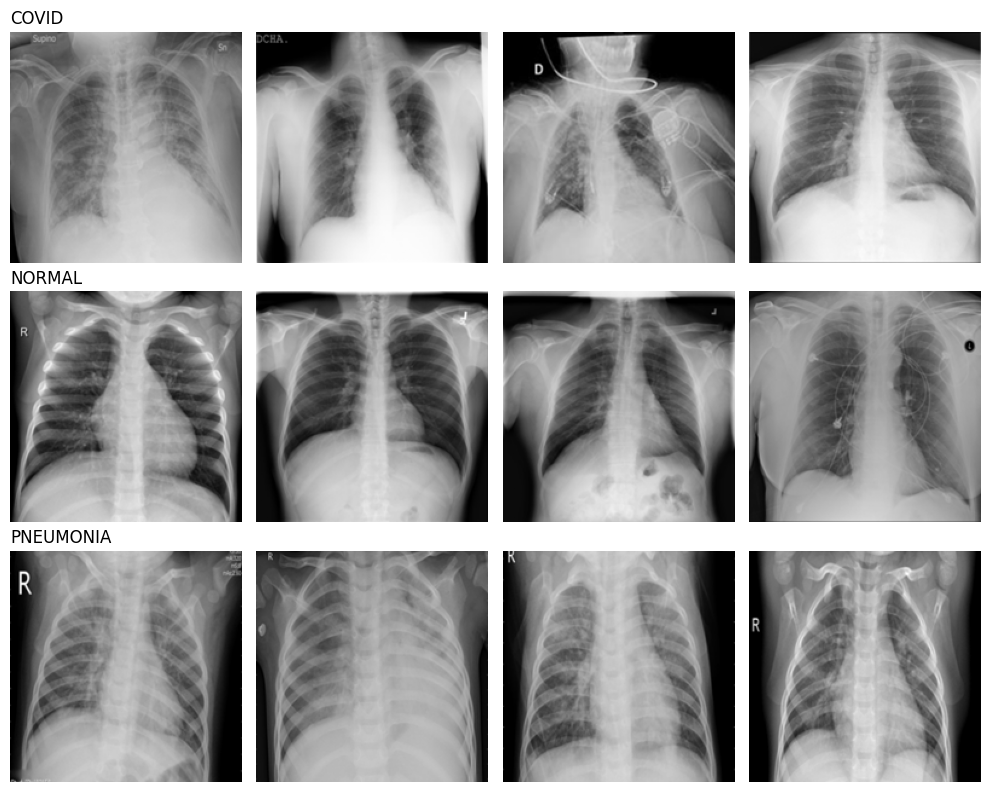

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for row, (name, files) in enumerate(zip(class_names, fnames)):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(preprocessor(files[col]))
        ax.axis('off')
        if col == 0:
            ax.set_title(name, loc='left')
plt.tight_layout()
plt.show()

### Split into Training, Validation, and Test Sets

In [ ]:
# 20% test set, then 20% of the remaining data as a validation set (64% / 16% / 20% overall)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
del X  # free memory

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)
del X_train_full, y_train_full  # free memory

print('Training:  ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:      ', X_test.shape, y_test.shape)

Training:   (2582, 192, 192, 3) (2582, 3)
Validation: (646, 192, 192, 3) (646, 3)
Test:       (807, 192, 192, 3) (807, 3)


### Optional: Save and Reload the Prepared Data

If Colab runs out of memory, use **Runtime → Restart session** and run the reload cell below instead of all of Section 0 (run the **Import Libraries** cell first). The saved files are stored in this Colab session only, so they are lost if the session disconnects.

In [ ]:
# Save the prepared data (optional)
for name, arr in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test),
                  ('y_train', y_train), ('y_val', y_val), ('y_test', y_test)]:
    np.save(f'{name}.npy', np.asarray(arr))

In [ ]:
# Reload the prepared data (optional)
X_train, X_val, X_test = (np.load(f'{name}.npy') for name in ['X_train', 'X_val', 'X_test'])
y_train, y_val, y_test = (pd.DataFrame(np.load(f'{name}.npy'), columns=class_names)
                          for name in ['y_train', 'y_val', 'y_test'])

---

## 1. Dataset and Exploratory Data Analysis

### Describe the Dataset

Describe the dataset using basic statistics and sample images. For example, show the number of images per class in each split, the image dimensions, pixel intensity statistics, and several sample images from each class.

,Train,Validation,Test,Total
COVID,860,216,269,1345
NORMAL,861,215,269,1345
PNEUMONIA,861,215,269,1345
Total,2582,646,807,4035


Image tensor shape (H, W, C): (192, 192, 3) | dtype: float32
R, G and B channels identical (grayscale X-rays copied to 3 channels): True
Original file size and mode (before resizing): (299, 299) L


,Images,Mean pixel,Std pixel,Min,Max,Per-image mean (avg),Per-image mean (std),Per-image contrast (avg std)
Class,,,,,,,,
COVID,860,0.544,0.244,0.0,1.0,0.544,0.101,0.215
NORMAL,861,0.504,0.259,0.0,1.0,0.504,0.085,0.242
PNEUMONIA,861,0.491,0.247,0.0,1.0,0.491,0.075,0.232


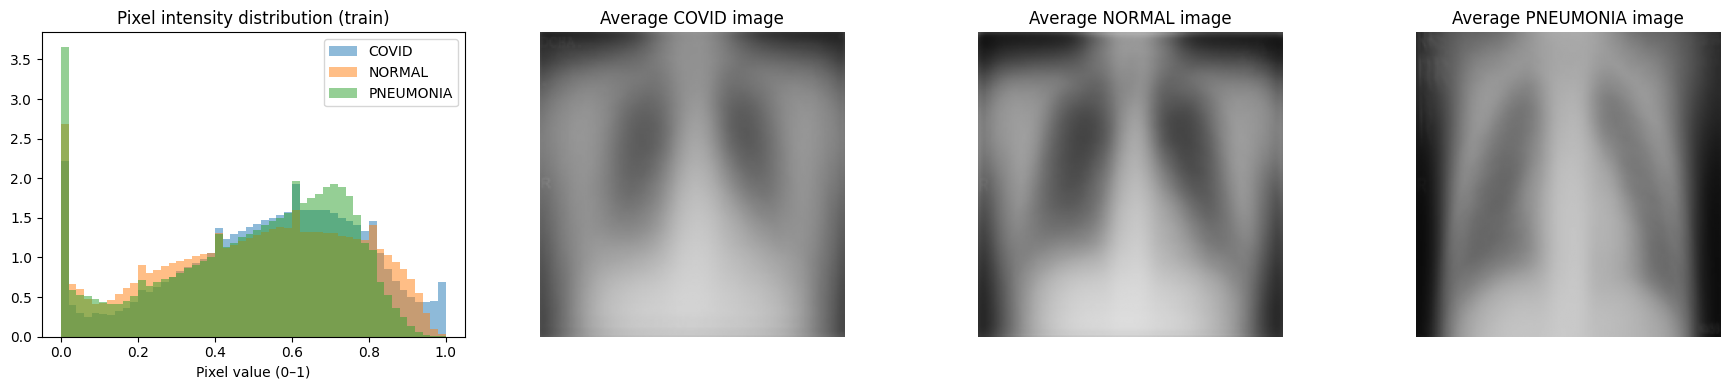

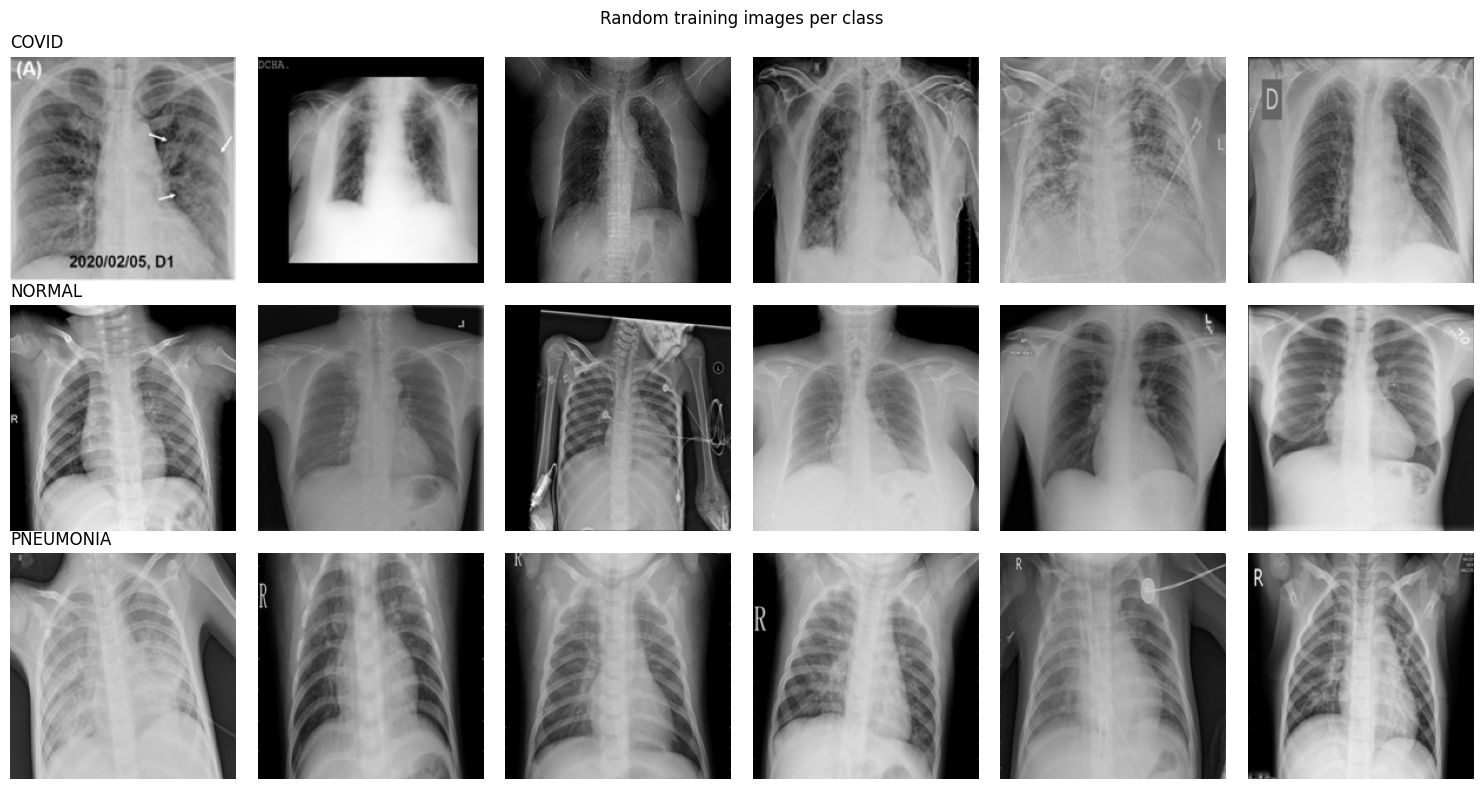

In [ ]:
# Plain NumPy versions of the one-hot labels (works whether y_* are DataFrames or arrays)
y_train_arr, y_val_arr, y_test_arr = (np.asarray(a, dtype='float32') for a in (y_train, y_val, y_test))
train_lbl = y_train_arr.argmax(1)

# 1) Number of images per class in each split
split_counts = pd.DataFrame({'Train': y_train_arr.sum(0),
                             'Validation': y_val_arr.sum(0),
                             'Test': y_test_arr.sum(0)}, index=class_names).astype(int)
split_counts['Total'] = split_counts.sum(axis=1)
split_counts.loc['Total'] = split_counts.sum()
display(split_counts)

# 2) Image dimensions and channels
print('Image tensor shape (H, W, C):', X_train.shape[1:], '| dtype:', X_train.dtype)
same_channels = (np.allclose(X_train[:200, ..., 0], X_train[:200, ..., 1]) and
                 np.allclose(X_train[:200, ..., 0], X_train[:200, ..., 2]))
print('R, G and B channels identical (grayscale X-rays copied to 3 channels):', same_channels)
with Image.open(fnames[0][0]) as im:
    print('Original file size and mode (before resizing):', im.size, im.mode)

# 3) Pixel intensity statistics per class (training set, one channel is enough since they are identical)
rows = []
for i, c in enumerate(class_names):
    imgs = X_train[train_lbl == i, ..., 0]
    per_img_mean = imgs.mean(axis=(1, 2))
    per_img_std = imgs.std(axis=(1, 2))
    rows.append({'Class': c, 'Images': len(imgs),
                 'Mean pixel': imgs.mean(), 'Std pixel': imgs.std(),
                 'Min': imgs.min(), 'Max': imgs.max(),
                 'Per-image mean (avg)': per_img_mean.mean(),
                 'Per-image mean (std)': per_img_mean.std(),
                 'Per-image contrast (avg std)': per_img_std.mean()})
pixel_stats = pd.DataFrame(rows).set_index('Class')
display(pixel_stats.round(3))

# 4) Intensity histograms and average image per class
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, c in enumerate(class_names):
    imgs = X_train[train_lbl == i, ..., 0]
    axes[0].hist(imgs[:, ::4, ::4].ravel(), bins=50, alpha=0.5, density=True, label=c)
    axes[i + 1].imshow(imgs.mean(axis=0), cmap='gray', vmin=0, vmax=1)
    axes[i + 1].set_title(f'Average {c} image')
    axes[i + 1].axis('off')
axes[0].set_title('Pixel intensity distribution (train)')
axes[0].set_xlabel('Pixel value (0–1)')
axes[0].legend()
plt.tight_layout()
plt.show()

# 5) Several random training images from each class
rng_np = np.random.default_rng(0)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for i, c in enumerate(class_names):
    idx = rng_np.choice(np.where(train_lbl == i)[0], 6, replace=False)
    for j, k in enumerate(idx):
        axes[i, j].imshow(X_train[k])
        axes[i, j].axis('off')
    axes[i, 0].set_title(c, loc='left')
plt.suptitle('Random training images per class')
plt.tight_layout()
plt.show()

Describe what you observe. How do the three classes look different, and how might that help or challenge a model?

All images end up as 192×192×3 arrays scaled to 0–1. The original files are 299×299 grayscale PNGs, so the three color channels are just copies of each other (we checked, and they are identical). They are only stored as RGB so the ImageNet models can take them. The stratified split gives 2,582 training, 646 validation and 807 test images, with roughly the same number per class in each split (860–861 / 215–216 / 269).

Looking at the samples, normal X-rays have dark, clear lungs and you can see the ribs and the edge of the heart and diaphragm sharply. The COVID images look hazier, with whitish "ground-glass" areas that are often in both lungs and toward the outer edges. Viral pneumonia images have patchier, more spread-out opacities, and a lot of them seem to be children (smaller chests, different proportions), so the framing and exposure vary more.

The pixel statistics agree with what we see. COVID images are the brightest on average (mean 0.544, vs. 0.504 for normal and 0.491 for viral pneumonia) and have the lowest contrast (average per-image std 0.215 vs. 0.242 for normal), which makes sense if the opacities are filling in the normally dark lung area. COVID also varies the most from image to image in brightness (0.101 vs. 0.085 and 0.075), probably because those images come from more different sources. In the average image per class you can see differences in body shape and positioning, not just inside the lungs.

For a model, the opacity patterns are a real signal that conv filters should be able to pick up, and normal vs. sick lungs look pretty different. But the brightness differences are small (around 0.05) and overlap a lot, so the model can't just rely on brightness. Mild COVID cases can also look close to normal, so we expect some COVID/normal confusion. One concern is that each class partly comes from different hospitals or datasets (e.g. the pediatric pneumonia images, text markers, borders). A CNN could learn to recognize the source instead of the disease, so a high score here doesn't necessarily mean it would work on X-rays from a new hospital.

### Class Balance

The full dataset is **imbalanced**, but Section 0 uses the same number of images from each class. Using `original_counts`, plot the number of images per class in the full dataset next to the number used in this project.

,Full dataset,Used in this project,Share of full dataset (%)
COVID,3616,1345,23.9
NORMAL,10192,1345,67.3
PNEUMONIA,1345,1345,8.9


Imbalance ratio (largest / smallest class): 7.58
Images discarded by undersampling: 11,118 of 15,153


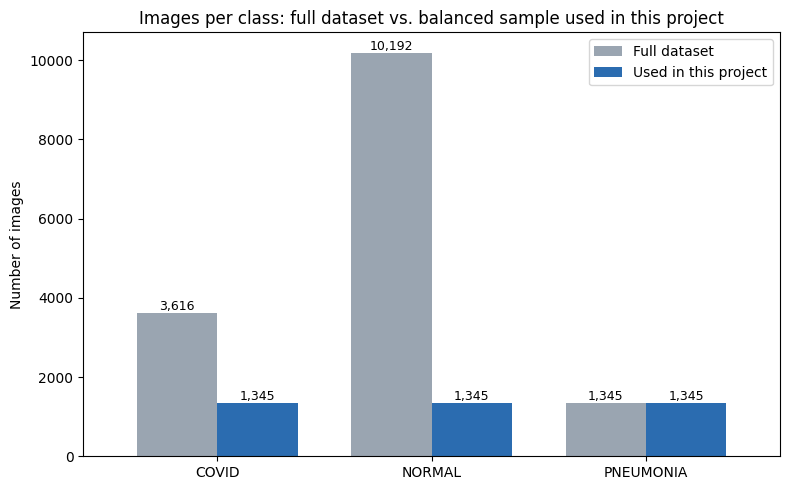

In [ ]:
used_counts = {c: n_per_class for c in class_names}
balance = pd.DataFrame({'Full dataset': original_counts, 'Used in this project': used_counts})
balance['Share of full dataset (%)'] = (100 * balance['Full dataset'] / balance['Full dataset'].sum()).round(1)
display(balance)
print('Imbalance ratio (largest / smallest class):',
      round(max(original_counts.values()) / min(original_counts.values()), 2))
print(f"Images discarded by undersampling: {balance['Full dataset'].sum() - balance['Used in this project'].sum():,} "
      f"of {balance['Full dataset'].sum():,}")

ax = balance[['Full dataset', 'Used in this project']].plot(kind='bar', figsize=(8, 5), rot=0,
                                                            color=['#9aa5b1', '#2b6cb0'], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', fontsize=9)
ax.set_ylabel('Number of images')
ax.set_title('Images per class: full dataset vs. balanced sample used in this project')
plt.tight_layout()
plt.show()

Answer the following:

1. How imbalanced is the full dataset?
2. Common strategies for imbalanced data include **class weighting**, **oversampling**, **undersampling**, and **augmentation**. Which of these does Section 0 use, and why do you think it was chosen?
3. If you trained on all the images instead, which strategy would you use? How would you expect it to change model performance?

1. The full dataset is quite imbalanced. Out of 15,153 images in these three classes, 10,192 are normal (67.3%), 3,616 are COVID (23.9%) and only 1,345 are viral pneumonia (8.9%). Normal is about 7.6 times bigger than viral pneumonia. A model that just predicted "normal" every time would already get 67% accuracy on the full data, so accuracy alone would be misleading.

2. Section 0 uses random **undersampling**: it keeps 1,345 random images per class (the size of the smallest class) and throws away the rest, which is 11,118 images or about 73% of the data. We think the main reason is memory. All 15,153 images as 192×192×3 float32 arrays would be around 6.7 GB before any copies, which is too much for free Colab, while the sample is about 1.8 GB. It also keeps things simple: with balanced classes, accuracy is a fair metric, we don't need class weights, and training is fast enough to try several models. The downside is that we lose most of the normal and COVID images, which could have helped the models learn more variety.

3. If we used all the images, we would load them from disk in batches with a `tf.data` pipeline instead of putting everything in memory, and use **class weights** (inverse to class frequency) together with augmentation. For viral pneumonia, a bit of oversampling with augmentation could also help. We prefer class weights over plain oversampling because it doesn't throw away data or repeat the exact same images, so it is less likely to overfit. We would expect better overall accuracy and better COVID detection, since the model would see about four times more data. Without weighting, the model would probably lean toward predicting normal and miss more pneumonia cases. We would also report macro-F1 and per-class recall, because the test set would be imbalanced too.

### Practical Value

Reflect on the practical value of this classification task. Who might benefit from a model like this in a real-world setting?

We see this mainly as a screening or triage tool, not something that makes the diagnosis. In a busy hospital or ER, radiologists could use it to move X-rays that look like COVID or pneumonia to the front of the reading queue. Smaller clinics, for example in rural areas, often have an X-ray machine but no radiologist on site, so a quick preliminary result while they wait for a specialist could be useful. During an outbreak, public health or infection control teams could also use it to flag patients who might need to be isolated before PCR results come back, and patients would benefit indirectly from faster results.

That said, an X-ray alone can't confirm COVID (that needs a PCR or antigen test), and models trained on public datasets often do worse on images from other hospitals and machines. A real deployment would need outside validation, regulatory approval, and a doctor making the final call.

---

## 2. Baseline CNN Model

Build and train a **basic Convolutional Neural Network (CNN)** from scratch. It will be the baseline that you compare every other model with.

Train on `X_train` and `y_train`, pass `validation_data=(X_val, y_val)` to `fit`, and save the training history so that you can plot it in Section 5.

In [ ]:
BATCH_SIZE = 32
NUM_CLASSES = 3

def get_callbacks(patience=5):
    """Early stopping on validation loss (keeps the best weights) and learning-rate reduction on plateaus."""
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, verbose=1),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)]

# Training histories of every model, collected for the plots in Section 5
histories = {}      # model name -> dict of per-epoch metrics
ft_start = {}       # model name -> epoch where fine-tuning started (transfer models only)

# Baseline CNN: four Conv2D + MaxPooling2D blocks, then Flatten and Dense layers
keras.utils.set_random_seed(42)
baseline_model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    Conv2D(32, 3, activation='relu', padding='same'),
    MaxPooling2D(),
    Conv2D(64, 3, activation='relu', padding='same'),
    MaxPooling2D(),
    Conv2D(128, 3, activation='relu', padding='same'),
    MaxPooling2D(),
    Conv2D(128, 3, activation='relu', padding='same'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax'),
], name='baseline_cnn')

baseline_model.compile(optimizer=Adam(learning_rate=1e-3),
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])
baseline_model.summary()

baseline_history = baseline_model.fit(
    X_train, y_train_arr,
    validation_data=(X_val, y_val_arr),
    epochs=30, batch_size=BATCH_SIZE,
    callbacks=get_callbacks(patience=5),
    verbose=2)
histories['Baseline CNN'] = baseline_history.history

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,600,643 (9.92 MB)

 Trainable params: 2,600,643 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
81/81 - 38s - 467ms/step - accuracy: 0.7115 - loss: 0.6661 - val_accuracy: 0.8127 - val_loss: 0.5001 - learning_rate: 0.0010
Epoch 2/30
81/81 - 4s - 46ms/step - accuracy: 0.8521 - loss: 0.3938 - val_accuracy: 0.8529 - val_loss: 0.4129 - learning_rate: 0.0010
Epoch 3/30
81/81 - 4s - 45ms/step - accuracy: 0.8962 - loss: 0.3041 - val_accuracy: 0.8452 - val_loss: 0.3923 - learning_rate: 0.0010
Epoch 4/30
81/81 - 4s - 46ms/step - accuracy: 0.9055 - loss: 0.2455 - val_accuracy: 0.8483 - val_loss: 0.4035 - learning_rate: 0.0010
Epoch 5/30
81/81 - 4s - 47ms/step - accuracy: 0.9191 - loss: 0.2175 - val_accuracy: 0.9118 - val_loss: 0.2612 - learning_rate: 0.0010
Epoch 6/30
81/81 - 4s - 45ms/step - accuracy: 0.9396 - loss: 0.1738 - val_accuracy: 0.9040 - val_loss: 0.3406 - learning_rate: 0.0010
Epoch 7/30

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 - 4s - 45ms/step - accuracy: 0.9508 - loss: 0.1440 - val_accuracy: 0.9211 - val_loss: 0.2991 - learn

### Evaluate the Baseline

Report the model's **training, validation, and test** performance.

=== Baseline CNN ===


,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
Baseline CNN,0.9562,0.956,0.9118,0.9112,0.9095,0.9089,0.2238,0.9257,0.8327,0.9703,2.6006


              precision    recall  f1-score   support

       COVID      0.871     0.926     0.897       269
      NORMAL      0.926     0.833     0.877       269
   PNEUMONIA      0.935     0.970     0.953       269

    accuracy                          0.910       807
   macro avg      0.911     0.910     0.909       807
weighted avg      0.911     0.910     0.909       807



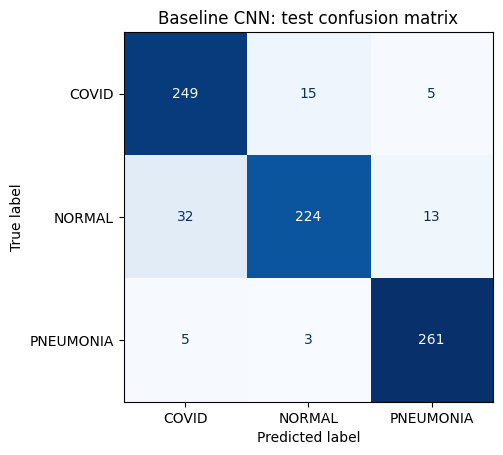

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

results = {}   # model name -> dict of metrics (filled by evaluate_model)

def evaluate_model(model, name, show_details=True):
    """Compute accuracy and macro-F1 on train / val / test, plus test loss and per-class test recall."""
    row = {}
    for split, X_, y_ in [('Train', X_train, y_train_arr), ('Val', X_val, y_val_arr), ('Test', X_test, y_test_arr)]:
        probs = model.predict(X_, batch_size=64, verbose=0)
        pred, true = probs.argmax(1), y_.argmax(1)
        row[f'{split} acc'] = (pred == true).mean()
        row[f'{split} macro-F1'] = f1_score(true, pred, average='macro', zero_division=0)
    row['Test loss'] = float(keras.losses.CategoricalCrossentropy()(y_test_arr, probs))
    cm = confusion_matrix(true, pred)
    for i, c in enumerate(class_names):
        row[f'Test recall {c}'] = cm[i, i] / cm[i].sum()
    row['Params (M)'] = model.count_params() / 1e6
    results[name] = row

    if show_details:
        print(f'=== {name} ===')
        display(pd.DataFrame([row], index=[name]).round(4))
        print(classification_report(true, pred, target_names=class_names, digits=3, zero_division=0))
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', colorbar=False)
        plt.title(f'{name}: test confusion matrix')
        plt.show()
    return row

evaluate_model(baseline_model, 'Baseline CNN');

### Describe the Baseline

Clearly describe the architecture, loss function, optimizer, evaluation metrics, and training configuration (e.g., batch size, number of epochs) you used, and why.

The baseline is a simple CNN with about 2.6M parameters, most of them in the first dense layer. It has four conv blocks (Conv2D 3×3 with ReLU and same padding, then 2×2 max pooling) with 32, 64, 128 and 128 filters. Each block halves the image size (192 → 96 → 48 → 24 → 12) while adding more feature maps, so the early layers can pick up edges and textures and the later ones bigger patterns like lung shape and opacities. After that we flatten, use a Dense(128) layer with ReLU, Dropout(0.5) to limit overfitting, and a 3-unit softmax output. We left out batch norm and augmentation on purpose so that it works as a plain reference point.

We used categorical cross-entropy as the loss since the labels are one-hot and the output is softmax, and Adam with a learning rate of 1e-3, which is a common default for training from scratch and doesn't need much tuning. During training we tracked accuracy, which is fine here because the classes are balanced. For evaluation we also report macro-F1 and recall per class, since for screening it matters more not to miss sick patients than to get the best overall accuracy.

Batch size was 32, which fits easily on the T4 GPU. We set a maximum of 30 epochs but used early stopping on validation loss (patience 5, restoring the best weights) so we didn't have to guess the number of epochs, plus ReduceLROnPlateau to halve the learning rate if validation loss stalled for 2 epochs. We used the same batch size, callbacks and splits for every model so the comparison is fair.

Training stopped after 10 epochs and kept the weights from epoch 5 (val accuracy 91.2%, val loss 0.261). After epoch 5 the training loss kept going down (0.22 to 0.06) but validation loss went back up, so the model was starting to overfit. The final result was 95.6% train, 91.2% validation and 91.0% test accuracy (macro-F1 0.909). Its weakest class was normal, with only 83.3% recall, meaning it called quite a few healthy X-rays COVID or pneumonia.

---

## 3. Transfer Learning with ResNet

Use **ResNet50**, pre-trained on ImageNet, as the starting point for a new model:

1. Load ResNet50 without its top classification layer, freeze its layers, and add your own classification head. Train only the new head.
2. **Fine-tune** the model: unfreeze some of the top ResNet layers and continue training with a low learning rate.
3. Compare its performance with the baseline CNN.

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def build_transfer_model(base_cls, preprocess_fn, name, dense_units=256, dropout=0.3):
    """Pre-trained ImageNet backbone (frozen) + new classification head.
    Our images are in [0, 1], so they are multiplied by 255 before the model's own preprocess_input."""
    keras.utils.set_random_seed(42)
    base = base_cls(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = preprocess_fn(inputs * 255.0)
    x = base(x, training=False)   # keep BatchNorm layers in inference mode, also during fine-tuning
    x = GlobalAveragePooling2D()(x)
    x = Dropout(dropout)(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dropout(dropout)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax')(x)
    model = Model(inputs, outputs, name=name)
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    return model, base

def merge_histories(*hists):
    """Join the histories of the head-training and fine-tuning phases into one."""
    out = {}
    for h in hists:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

# Load ResNet50 (ImageNet weights, no top), freeze it, and add a new head
resnet_model, resnet_base = build_transfer_model(ResNet50, preprocess_input, 'resnet50_transfer')
print('Trainable parameters (head only):',
      sum(int(np.prod(w.shape)) for w in resnet_model.trainable_weights))

# Phase 1: train only the new head
resnet_head_history = resnet_model.fit(
    X_train, y_train_arr,
    validation_data=(X_val, y_val_arr),
    epochs=15, batch_size=BATCH_SIZE,
    callbacks=get_callbacks(patience=5),
    verbose=2)

# Record the frozen-backbone result so we can see what fine-tuning adds
evaluate_model(resnet_model, 'ResNet50 (frozen, head only)', show_details=False)
pd.DataFrame(results).T.round(4)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Trainable parameters (head only): 525315
Epoch 1/15
81/81 - 65s - 807ms/step - accuracy: 0.7851 - loss: 0.5677 - val_accuracy: 0.8808 - val_loss: 0.3040 - learning_rate: 0.0010
Epoch 2/15
81/81 - 6s - 76ms/step - accuracy: 0.8803 - loss: 0.2976 - val_accuracy: 0.9071 - val_loss: 0.2512 - learning_rate: 0.0010
Epoch 3/15
81/81 - 6s - 74ms/step - accuracy: 0.8989 - loss: 0.2640 - val_accuracy: 0.9009 - val_loss: 0.2226 - learning_rate: 0.0010
Epoch 4/15
81/81 - 6s - 75ms/step - accuracy: 0.9175 - loss: 0.2157 - val_accuracy: 0.9149 - val_loss: 0.1960 - learning_rate: 0.0010
Epoch 5/15
81/81 - 6s - 73ms/step - accuracy: 0.9311 - loss: 0.1847 - val_accuracy: 0.9334 - val_loss: 0.1868 - learning_rate: 0.0010
Epoch 6/15
81/81 - 6s - 73ms/step - accuracy: 0.9194 - loss: 0.1900 - val_accuracy: 0.9164 - val_loss: 0.2033 - learning_rate: 0.0010
Epoch 7/15
81/81 - 10s - 128ms/step - accuracy: 0.9357 - loss: 0.1583 - val_accuracy: 0.9489 - val_los

,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
Baseline CNN,0.9562,0.9560,0.9118,0.9112,0.9095,0.9089,0.2238,0.9257,0.8327,0.9703,2.6006
"ResNet50 (frozen, head only)",0.9919,0.9919,0.9536,0.9533,0.9492,0.9490,0.1314,0.9219,0.9294,0.9963,24.1130


### Fine-Tune ResNet

Unfreeze some of the top ResNet layers, recompile with a low learning rate (e.g., `1e-5`), and continue training.

In [ ]:
def fine_tune(model, base, unfreeze_from, learning_rate=1e-5, epochs=15, patience=5):
    """Unfreeze the backbone from the first layer whose name starts with `unfreeze_from` to the end.
    BatchNormalization layers stay frozen. Recompile with a low learning rate and continue training."""
    base.trainable = True
    unfreeze = False
    for layer in base.layers:
        if layer.name.startswith(unfreeze_from):
            unfreeze = True
        layer.trainable = unfreeze and not isinstance(layer, BatchNormalization)
    n_trainable = sum(l.trainable for l in base.layers)
    print(f'Unfrozen backbone layers: {n_trainable} of {len(base.layers)} (from "{unfreeze_from}")')
    print('Trainable parameters:', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model.fit(X_train, y_train_arr,
                     validation_data=(X_val, y_val_arr),
                     epochs=epochs, batch_size=BATCH_SIZE,
                     callbacks=get_callbacks(patience=patience),
                     verbose=2)

# Phase 2: unfreeze the last stage of ResNet50 (all "conv5_" layers) and train with lr = 1e-5
resnet_ft_history = fine_tune(resnet_model, resnet_base, unfreeze_from='conv5_', learning_rate=1e-5)

histories['ResNet50'] = merge_histories(resnet_head_history, resnet_ft_history)
ft_start['ResNet50'] = len(resnet_head_history.history['loss'])

Unfrozen backbone layers: 22 of 175 (from "conv5_")
Trainable parameters: 15478787
Epoch 1/15
81/81 - 43s - 525ms/step - accuracy: 0.9682 - loss: 0.0820 - val_accuracy: 0.9505 - val_loss: 0.1222 - learning_rate: 1.0000e-05
Epoch 2/15
81/81 - 15s - 191ms/step - accuracy: 0.9841 - loss: 0.0447 - val_accuracy: 0.9582 - val_loss: 0.1451 - learning_rate: 1.0000e-05
Epoch 3/15

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
81/81 - 8s - 101ms/step - accuracy: 0.9923 - loss: 0.0282 - val_accuracy: 0.9598 - val_loss: 0.1428 - learning_rate: 1.0000e-05
Epoch 4/15
81/81 - 8s - 100ms/step - accuracy: 0.9969 - loss: 0.0169 - val_accuracy: 0.9628 - val_loss: 0.1327 - learning_rate: 5.0000e-06
Epoch 5/15

Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
81/81 - 8s - 101ms/step - accuracy: 0.9965 - loss: 0.0109 - val_accuracy: 0.9659 - val_loss: 0.1387 - learning_rate: 5.0000e-06
Epoch 6/15
81/81 - 8s - 100ms/step - accuracy: 0.9977 - loss: 0.00

### Evaluate and Compare with the Baseline

=== ResNet50 (fine-tuned) ===


,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
ResNet50 (fine-tuned),0.995,0.995,0.9505,0.9503,0.9554,0.9553,0.1146,0.9071,0.9703,0.9888,24.113


              precision    recall  f1-score   support

       COVID      0.976     0.907     0.940       269
      NORMAL      0.913     0.970     0.941       269
   PNEUMONIA      0.982     0.989     0.985       269

    accuracy                          0.955       807
   macro avg      0.957     0.955     0.955       807
weighted avg      0.957     0.955     0.955       807



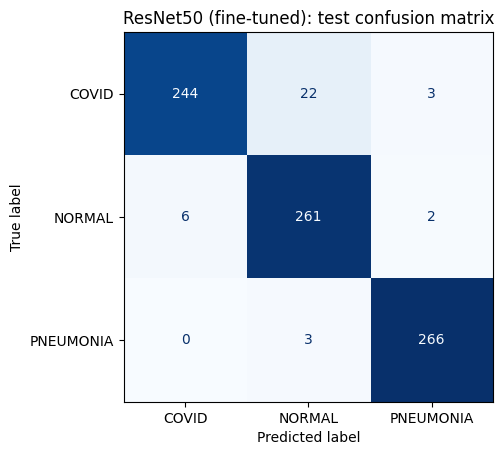

,Train acc,Val acc,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
Baseline CNN,0.9562,0.9118,0.9095,0.9089,0.2238,0.9257,0.8327,0.9703,2.6006
"ResNet50 (frozen, head only)",0.9919,0.9536,0.9492,0.9490,0.1314,0.9219,0.9294,0.9963,24.1130
ResNet50 (fine-tuned),0.9950,0.9505,0.9554,0.9553,0.1146,0.9071,0.9703,0.9888,24.1130


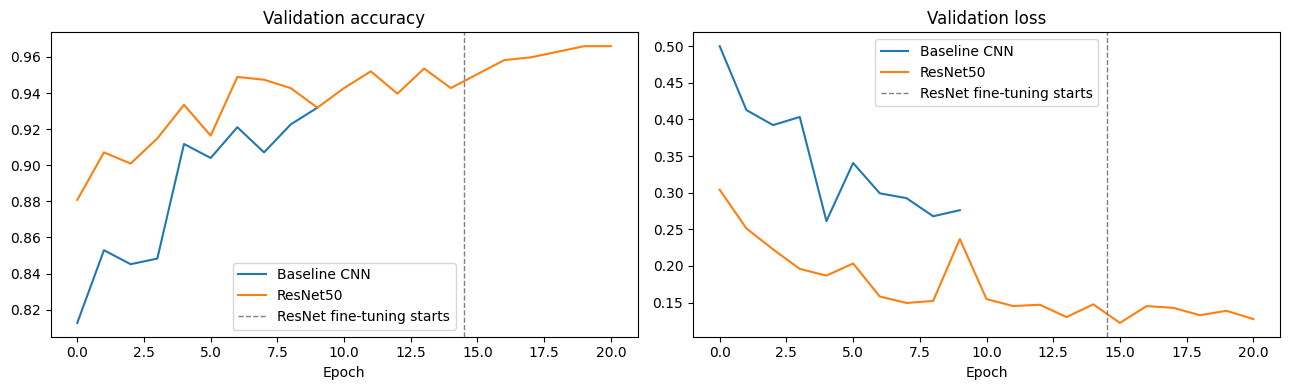

In [ ]:
evaluate_model(resnet_model, 'ResNet50 (fine-tuned)')

compare_cols = ['Train acc', 'Val acc', 'Test acc', 'Test macro-F1', 'Test loss',
                'Test recall COVID', 'Test recall NORMAL', 'Test recall PNEUMONIA', 'Params (M)']
display(pd.DataFrame(results).T.loc[['Baseline CNN', 'ResNet50 (frozen, head only)', 'ResNet50 (fine-tuned)'],
                                    compare_cols].round(4))

# Validation accuracy and loss per epoch: baseline vs. ResNet50
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in ['Baseline CNN', 'ResNet50']:
    axes[0].plot(histories[name]['val_accuracy'], label=name)
    axes[1].plot(histories[name]['val_loss'], label=name)
for ax in axes:
    ax.axvline(ft_start['ResNet50'] - 0.5, ls='--', c='gray', lw=1, label='ResNet fine-tuning starts')
    ax.set_xlabel('Epoch')
    ax.legend()
axes[0].set_title('Validation accuracy')
axes[1].set_title('Validation loss')
plt.tight_layout()
plt.show()

### Discussion

How does the ResNet model compare with the baseline CNN? How do pre-trained features influence your model's training (e.g., speed, stability) and generalization?

ResNet50 did clearly better than the baseline. Even with the whole backbone frozen and only our new head trained, it got 94.9% test accuracy compared to 91.0% for the baseline. Fine-tuning the conv5 stage brought it up to 95.5% (macro-F1 0.955) and lowered the test loss from 0.131 to 0.115, compared to 0.224 for the baseline. The biggest improvement was for normal X-rays, where recall went from 83.3% to 97.0%, so there are a lot fewer false alarms. Viral pneumonia was almost always correct (98.9% recall). COVID was actually its weakest class at 90.7% recall, a bit lower than the baseline's 92.6%, and most of those mistakes were COVID images predicted as normal.

The pre-trained features made training a lot faster and smoother. After just one epoch of training the head, validation accuracy was already 88.1%, which the baseline only reached around epoch 5 (it started at 81%). ResNet's validation loss went down fairly steadily from 0.30 to 0.13 over 14 epochs with just one spike at epoch 10, while the baseline's validation loss bounced around (0.26, 0.34, 0.29) and started increasing after epoch 5. The head-only epochs were also cheap, around 6 seconds each, since nothing is backpropagated through the frozen layers.

Fine-tuning was interesting because it peaked almost right away: the best validation loss (0.122) was after the first fine-tuning epoch, and early stopping ended this phase after 6 epochs. Training accuracy went up to 99.8% while validation loss didn't improve, so with around 15M unfrozen parameters and only 2,582 training images, the model starts overfitting quickly even with a 1e-5 learning rate. This is why fine-tuning only added about half a point.

For generalization, it's notable that ResNet50 has about 9 times more parameters than the baseline (24.1M vs 2.6M) but still overfits less. Its validation and test accuracy (95.1% and 95.5%) are close and both well above the baseline. Our explanation is that the ImageNet features (edges, textures, shapes) already work reasonably well and don't have to be learned again from a small dataset, so the model has less room to memorize noise. Keeping batch norm in inference mode and using a low learning rate also helped the top layers adjust without wrecking what they learned before. One thing to keep in mind is that ImageNet is natural photos, not X-rays, which is probably why the frozen model already works well but fine-tuning still helps a bit. And as mentioned in Section 1, better accuracy doesn't rule out that both models use shortcuts specific to this dataset.

---

## 4. Additional Architectures

Implement **three additional models** of your choice. For example, a deeper custom CNN, or pre-trained models such as VGG19, InceptionV3, MobileNetV2, DenseNet121, or EfficientNet.

Use the same `X_train`, `X_val`, and `X_test` splits and the same preprocessing for every model, so that the comparison is fair. If you use another pre-trained model, apply its own `preprocess_input` function, as in Section 3.

### Additional Model 1

Model: "deeper_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 192, 192, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 192, 192, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 192, 192, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 192, 192, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 192, 192, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 192, 192, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 96, 96, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 96, 96, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 96, 96, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 96, 96, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 48, 48, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 48, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 48, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 24, 24, 128)    │             

 Total params: 1,208,419 (4.61 MB)

 Trainable params: 1,206,499 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/40
81/81 - 71s - 875ms/step - accuracy: 0.6832 - loss: 0.7288 - val_accuracy: 0.3328 - val_loss: 2.7292 - learning_rate: 0.0010
Epoch 2/40
81/81 - 26s - 322ms/step - accuracy: 0.7630 - loss: 0.5424 - val_accuracy: 0.2616 - val_loss: 1.7688 - learning_rate: 0.0010
Epoch 3/40
81/81 - 20s - 246ms/step - accuracy: 0.7905 - loss: 0.4949 - val_accuracy: 0.3390 - val_loss: 2.4707 - learning_rate: 0.0010
Epoch 4/40

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 - 10s - 129ms/step - accuracy: 0.8083 - loss: 0.4402 - val_accuracy: 0.3576 - val_loss: 1.9187 - learning_rate: 0.0010
Epoch 5/40
81/81 - 10s - 129ms/step - accuracy: 0.8540 - loss: 0.3566 - val_accuracy: 0.3467 - val_loss: 2.9486 - learning_rate: 5.0000e-04
Epoch 6/40
81/81 - 10s - 127ms/step - accuracy: 0.8780 - loss: 0.3060 - val_accuracy: 0.5139 - val_loss: 1.3753 - learning_rate: 5.0000e-04
Epoch 7/40
81/81 - 10s - 126ms/step - accuracy: 0.8954 - loss: 0.2715 - val_accuracy: 0.7043 - val_

,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
Deeper CNN,0.9965,0.9965,0.9567,0.9566,0.9616,0.9617,0.1221,0.9442,0.9665,0.974,1.2084


              precision    recall  f1-score   support

       COVID      0.977     0.944     0.960       269
      NORMAL      0.932     0.967     0.949       269
   PNEUMONIA      0.978     0.974     0.976       269

    accuracy                          0.962       807
   macro avg      0.962     0.962     0.962       807
weighted avg      0.962     0.962     0.962       807



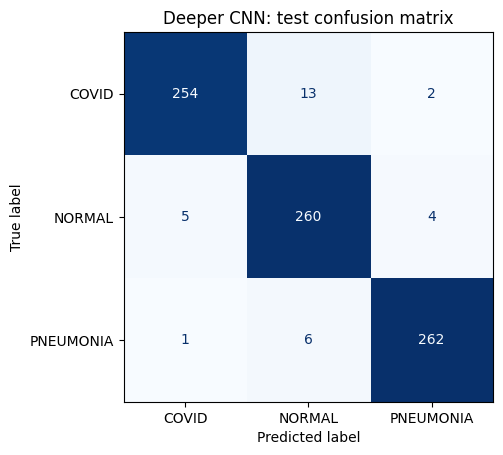

In [ ]:
# Additional Model 1: deeper custom CNN with batch normalization and global average pooling (trained from scratch)
def build_deep_cnn(augmentation=None, name='deeper_cnn'):
    keras.utils.set_random_seed(42)
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(inputs) if augmentation is not None else inputs
    for filters in [32, 64, 128, 256]:
        for _ in range(2):   # two 3x3 convolutions per block (VGG-style)
            x = Conv2D(filters, 3, padding='same', use_bias=False)(x)
            x = BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = MaxPooling2D()(x)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.4)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax')(x)
    model = Model(inputs, outputs, name=name)
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

deep_cnn = build_deep_cnn()
deep_cnn.summary()

deep_cnn_history = deep_cnn.fit(
    X_train, y_train_arr,
    validation_data=(X_val, y_val_arr),
    epochs=40, batch_size=BATCH_SIZE,
    callbacks=get_callbacks(patience=7),   # BatchNorm makes val loss noisier, so allow more patience
    verbose=2)
histories['Deeper CNN'] = deep_cnn_history.history

evaluate_model(deep_cnn, 'Deeper CNN');

### Additional Model 2

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
81/81 - 53s - 657ms/step - accuracy: 0.7382 - loss: 1.1945 - val_accuracy: 0.8978 - val_loss: 0.3163 - learning_rate: 0.0010
Epoch 2/15
81/81 - 12s - 146ms/step - accuracy: 0.8451 - loss: 0.4725 - val_accuracy: 0.9071 - val_loss: 0.2346 - learning_rate: 0.0010
Epoch 3/15
81/81 - 12s - 146ms/step - accuracy: 0.8513 - loss: 0.3823 - val_accuracy: 0.9118 - val_loss: 0.2505 - learning_rate: 0.0010
Epoch 4/15
81/81 - 12s - 147ms/step - accuracy: 0.8610 - loss: 0.3287 - val_accuracy: 0.9257 - val_loss: 0.2294 - learning_rate: 0.0010
Epoch 5/15
81/81 - 12s - 148ms/step - accuracy: 0.8799 - loss: 0.2815 - val_accuracy: 0.9257 - val_loss: 0.2107 - learning_rate: 0.0010
Epoch 6/15
81/81 - 12s - 146ms/step - accuracy: 0.8869 - loss: 0.2788 - val_accuracy: 0.9241 - val_loss: 0.2275 - learning_rate: 0.0010
Epoch 7/15
81/81 - 12s - 146ms/step - accuracy: 0.8966 - loss: 0.2723 - val_accuracy: 0.9241 - val_loss: 0.1921 - learning_rate: 0.00

,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
VGG19 (fine-tuned),1.0,1.0,0.9721,0.9722,0.9727,0.9728,0.0659,0.9591,0.9777,0.9814,20.1565


              precision    recall  f1-score   support

       COVID      0.977     0.959     0.968       269
      NORMAL      0.949     0.978     0.963       269
   PNEUMONIA      0.992     0.981     0.987       269

    accuracy                          0.973       807
   macro avg      0.973     0.973     0.973       807
weighted avg      0.973     0.973     0.973       807



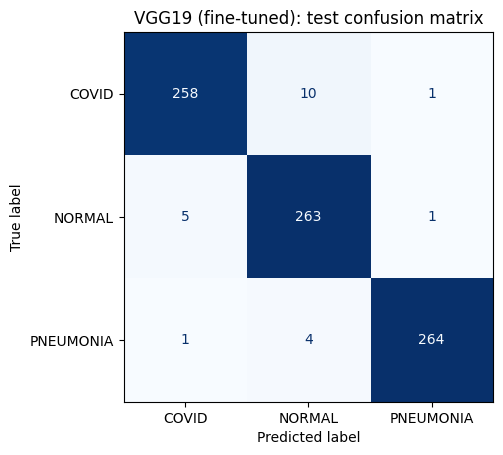

In [ ]:
# Additional Model 2: VGG19 pre-trained on ImageNet (frozen head training, then fine-tune block5)
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg19_preprocess

vgg_model, vgg_base = build_transfer_model(VGG19, vgg19_preprocess, 'vgg19_transfer')

vgg_head_history = vgg_model.fit(
    X_train, y_train_arr,
    validation_data=(X_val, y_val_arr),
    epochs=15, batch_size=BATCH_SIZE,
    callbacks=get_callbacks(patience=5),
    verbose=2)

vgg_ft_history = fine_tune(vgg_model, vgg_base, unfreeze_from='block5_', learning_rate=1e-5)

histories['VGG19'] = merge_histories(vgg_head_history, vgg_ft_history)
ft_start['VGG19'] = len(vgg_head_history.history['loss'])

evaluate_model(vgg_model, 'VGG19 (fine-tuned)');

### Additional Model 3

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
81/81 - 205s - 3s/step - accuracy: 0.7370 - loss: 0.6771 - val_accuracy: 0.8731 - val_loss: 0.3312 - learning_rate: 0.0010
Epoch 2/15
81/81 - 6s - 75ms/step - accuracy: 0.8338 - loss: 0.4016 - val_accuracy: 0.8932 - val_loss: 0.3001 - learning_rate: 0.0010
Epoch 3/15
81/81 - 10s - 123ms/step - accuracy: 0.8443 - loss: 0.3667 - val_accuracy: 0.8963 - val_loss: 0.3109 - learning_rate: 0.0010
Epoch 4/15
81/81 - 6s - 76ms/step - accuracy: 0.8621 - loss: 0.3306 - val_accuracy: 0.9118 - val_loss: 0.2483 - learning_rate: 0.0010
Epoch 5/15
81/81 - 6s - 72ms/step - accuracy: 0.8668 - loss: 0.3164 - val_accuracy: 0.9087 - val_loss: 0.2522 - learning_rate: 0.0010
Epoch 6/15

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 - 6s - 74ms/step - accuracy: 0.8675 - loss: 0.3071 - val_accuracy: 0.9009 - val_loss: 0.2562 - learning_rate: 0.0010
Epoch 7/15
81/81 - 6s - 75ms/step - accuracy: 0.8784 - loss: 0.280

,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
DenseNet121 (fine-tuned),0.9841,0.9841,0.9412,0.941,0.948,0.9479,0.1337,0.9071,0.948,0.9888,7.3007


              precision    recall  f1-score   support

       COVID      0.964     0.907     0.935       269
      NORMAL      0.904     0.948     0.926       269
   PNEUMONIA      0.978     0.989     0.983       269

    accuracy                          0.948       807
   macro avg      0.949     0.948     0.948       807
weighted avg      0.949     0.948     0.948       807



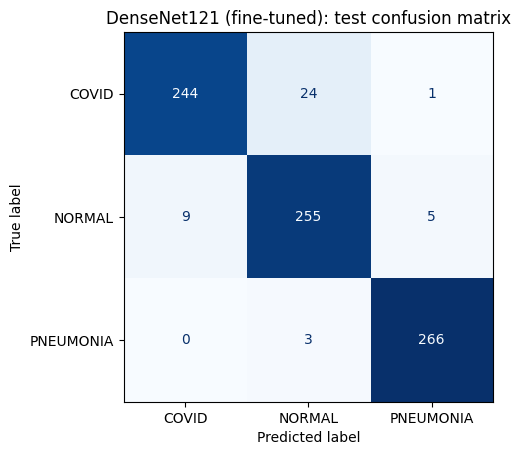

In [ ]:
# Additional Model 3: DenseNet121 pre-trained on ImageNet (frozen head training, then fine-tune the end of conv5)
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

densenet_model, densenet_base = build_transfer_model(DenseNet121, densenet_preprocess, 'densenet121_transfer')

densenet_head_history = densenet_model.fit(
    X_train, y_train_arr,
    validation_data=(X_val, y_val_arr),
    epochs=15, batch_size=BATCH_SIZE,
    callbacks=get_callbacks(patience=5),
    verbose=2)

# Unfreeze the last 8 dense blocks of the conv5 stage (conv5_block9 ... conv5_block16)
densenet_ft_history = fine_tune(densenet_model, densenet_base, unfreeze_from='conv5_block9_', learning_rate=1e-5)

histories['DenseNet121'] = merge_histories(densenet_head_history, densenet_ft_history)
ft_start['DenseNet121'] = len(densenet_head_history.history['loss'])

evaluate_model(densenet_model, 'DenseNet121 (fine-tuned)');

### Describe Your Models

For each of the three models, briefly describe its architecture and why you chose it.

**Model 1: Deeper CNN (from scratch).** We wanted to see if a better designed CNN trained from scratch could catch up to transfer learning. It has four blocks, each with two 3×3 convolutions (32, 64, 128, 256 filters), batch normalization and ReLU after every conv, and max pooling at the end of each block. Instead of flattening, it uses global average pooling, then Dropout(0.4), Dense(128), Dropout(0.4) and the softmax. Two stacked 3×3 convs see a larger area with fewer parameters than one big filter, batch norm makes training more stable, and global average pooling removes the huge flatten-to-dense layer from the baseline. So it is deeper but has fewer parameters (1.2M vs 2.6M). We also reused this model for the augmentation experiment in Section 6.

**Model 2: VGG19 (transfer learning).** VGG19 has 16 conv layers in five blocks of plain 3×3 convs and pooling, pre-trained on ImageNet. We used the same head as for ResNet50 (global average pooling, dropout, Dense(256), dropout, softmax), trained the head first with the backbone frozen, and then fine-tuned block5 with a learning rate of 1e-5. We chose it because it has no skip connections, so comparing it with ResNet50 shows whether the residual design matters here or whether the pre-trained features are doing most of the work. It is also used a lot in published COVID X-ray papers.

**Model 3: DenseNet121 (transfer learning).** In DenseNet, every layer in a dense block gets the outputs of all the layers before it, so features get reused. It is much smaller than the other two pre-trained models (about 7–8M parameters vs. 20–25M). We trained it the same two-phase way and fine-tuned the last 8 dense blocks of conv5. We picked it because it is the backbone of CheXNet, a well-known chest X-ray model, and because feature reuse is supposed to work well on small datasets.

All three use the same splits, batch size, loss, optimizer and callbacks as the baseline and ResNet50. The pre-trained ones each use their own `preprocess_input` after scaling the images back to 0–255.

---

## 5. Performance Comparison

### Test Performance of All Models

Evaluate **every model** (the baseline, ResNet, and your three additional models) on the same test set. Present the results in a table, and **highlight the model with the best test performance**.

Best test performance: VGG19 (fine-tuned) (accuracy 0.9727, macro-F1 0.9728)


,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Train acc,Val acc,Params (M),Epochs trained
VGG19 (fine-tuned),0.9727,0.9728,0.0659,0.9591,0.9777,0.9814,1.0000,0.9721,20.16,30
Deeper CNN,0.9616,0.9617,0.1221,0.9442,0.9665,0.9740,0.9965,0.9567,1.21,30
ResNet50 (fine-tuned),0.9554,0.9553,0.1146,0.9071,0.9703,0.9888,0.9950,0.9505,24.11,21
DenseNet121 (fine-tuned),0.9480,0.9479,0.1337,0.9071,0.9480,0.9888,0.9841,0.9412,7.30,30
Baseline CNN,0.9095,0.9089,0.2238,0.9257,0.8327,0.9703,0.9562,0.9118,2.60,10


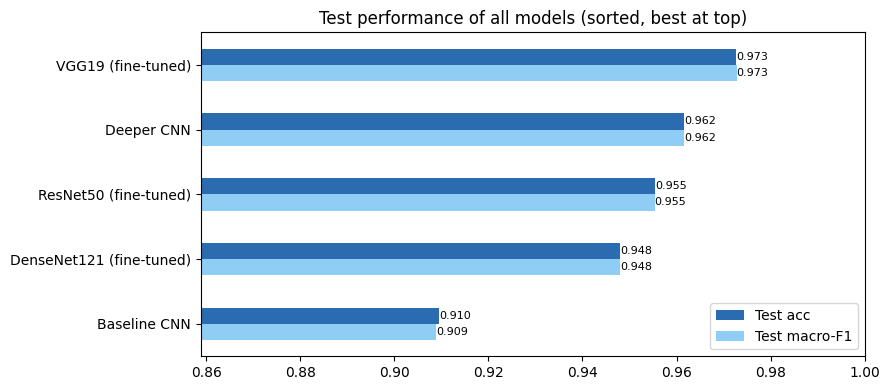

In [ ]:
main_models = ['Baseline CNN', 'ResNet50 (fine-tuned)', 'Deeper CNN', 'VGG19 (fine-tuned)', 'DenseNet121 (fine-tuned)']
show_cols = ['Test acc', 'Test macro-F1', 'Test loss',
             'Test recall COVID', 'Test recall NORMAL', 'Test recall PNEUMONIA',
             'Train acc', 'Val acc', 'Params (M)']

epochs_trained = {'Baseline CNN': len(histories['Baseline CNN']['loss']),
                  'ResNet50 (fine-tuned)': len(histories['ResNet50']['loss']),
                  'Deeper CNN': len(histories['Deeper CNN']['loss']),
                  'VGG19 (fine-tuned)': len(histories['VGG19']['loss']),
                  'DenseNet121 (fine-tuned)': len(histories['DenseNet121']['loss'])}

comparison = pd.DataFrame(results).T.loc[main_models, show_cols]
comparison['Epochs trained'] = pd.Series(epochs_trained)
comparison = comparison.sort_values(['Test acc', 'Test macro-F1'], ascending=False)

best_model_name = comparison.index[0]
print(f'Best test performance: {best_model_name} '
      f"(accuracy {comparison.loc[best_model_name, 'Test acc']:.4f}, "
      f"macro-F1 {comparison.loc[best_model_name, 'Test macro-F1']:.4f})")

def highlight_best(row):
    return ['background-color: #c6f6d5; font-weight: bold' if row.name == best_model_name else '' for _ in row]

display(comparison.style
        .apply(highlight_best, axis=1)
        .format({c: '{:.4f}' for c in show_cols if c != 'Params (M)'} | {'Params (M)': '{:.2f}'}))

# Bar chart of test accuracy and macro-F1
ax = comparison[['Test acc', 'Test macro-F1']].plot(kind='barh', figsize=(9, 4), color=['#2b6cb0', '#90cdf4'])
ax.invert_yaxis()
ax.set_xlim(max(0, comparison[['Test acc', 'Test macro-F1']].values.min() - 0.05), 1.0)
ax.set_title('Test performance of all models (sorted, best at top)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

### Hyperparameters and Training Strategies

Summarize the key hyperparameters and training strategies of each model in a table (e.g., learning rate, batch size, number of epochs, optimizer).

All models use the same data splits, input size (192 × 192 × 3), loss (categorical cross-entropy), batch size (32) and callbacks: **EarlyStopping** on validation loss with best-weight restoration, and **ReduceLROnPlateau** (factor 0.5, patience 2, min 1e-7). "Max epochs" is the limit; the number of epochs actually trained is in the *Epochs trained* column of the table above.

| Model | Pre-trained weights | Trainable layers | Optimizer | Learning rate | Batch size | Max epochs | Early-stopping patience | Regularization | Input preprocessing |
|---|---|---|---|---|---|---|---|---|---|
| Baseline CNN | None (from scratch) | All | Adam | 1e-3 | 32 | 30 | 5 | Dropout 0.5 | Pixels in [0, 1] |
| ResNet50 | ImageNet | Phase 1: head only · Phase 2: `conv5_` stage (BatchNorm frozen) | Adam | 1e-3 → 1e-5 | 32 | 15 + 15 | 5 + 5 | Dropout 0.3 ×2, frozen backbone | ×255, `resnet50.preprocess_input` |
| Deeper CNN | None (from scratch) | All | Adam | 1e-3 | 32 | 40 | 7 | BatchNorm, GAP, Dropout 0.4 ×2 | Pixels in [0, 1] |
| VGG19 | ImageNet | Phase 1: head only · Phase 2: `block5_` | Adam | 1e-3 → 1e-5 | 32 | 15 + 15 | 5 + 5 | Dropout 0.3 ×2, frozen backbone | ×255, `vgg19.preprocess_input` |
| DenseNet121 | ImageNet | Phase 1: head only · Phase 2: `conv5_block9`–`16` (BatchNorm frozen) | Adam | 1e-3 → 1e-5 | 32 | 15 + 15 | 5 + 5 | Dropout 0.3 ×2, frozen backbone | ×255, `densenet.preprocess_input` |
| Deeper CNN + augmentation (Section 6) | None (from scratch) | All | Adam | 1e-3 | 32 | 40 | 7 | Same as Deeper CNN + rotation, zoom, translation, contrast | Pixels in [0, 1] |

**Training strategies.**
- *From-scratch models* use a higher learning rate (1e-3) and train all layers at once.
- *Transfer models* use two phases: first the new head is trained with a frozen backbone (lr 1e-3), so random head weights do not send large, destructive gradients into the pre-trained layers; then only the top stage of the backbone is unfrozen and trained with a 100× smaller learning rate (1e-5). BatchNorm layers stay in inference mode, because re-estimating their statistics from batches of 32 X-rays would undo the pre-training.

### Training Curves

Plot the training and validation **loss** and **accuracy** over epochs for each model.

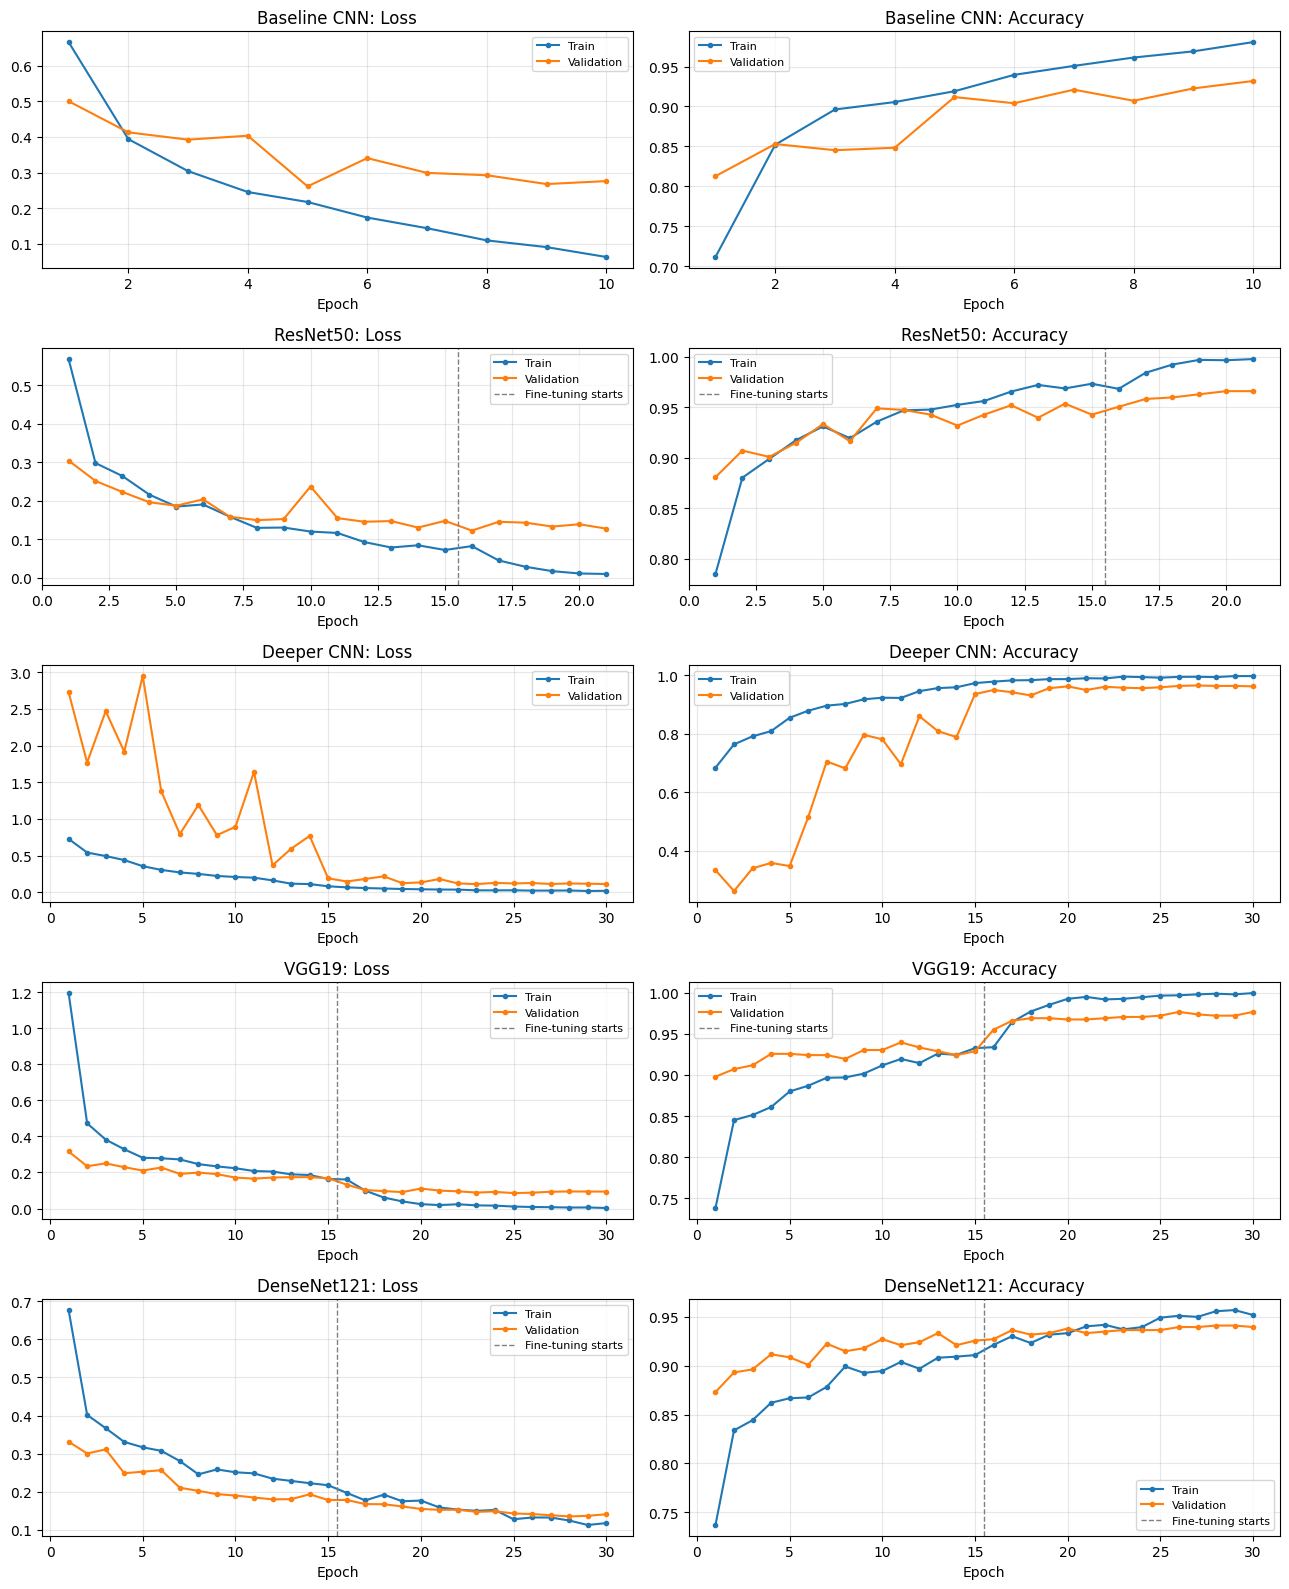

In [ ]:
plot_models = ['Baseline CNN', 'ResNet50', 'Deeper CNN', 'VGG19', 'DenseNet121']
fig, axes = plt.subplots(len(plot_models), 2, figsize=(13, 3.2 * len(plot_models)))
for r, name in enumerate(plot_models):
    h = histories[name]
    epochs = np.arange(1, len(h['loss']) + 1)
    for c, (metric, label) in enumerate([('loss', 'Loss'), ('accuracy', 'Accuracy')]):
        ax = axes[r, c]
        ax.plot(epochs, h[metric], 'o-', ms=3, label='Train')
        ax.plot(epochs, h[f'val_{metric}'], 'o-', ms=3, label='Validation')
        if name in ft_start:
            ax.axvline(ft_start[name] + 0.5, ls='--', c='gray', lw=1, label='Fine-tuning starts')
        ax.set_title(f'{name}: {label}')
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---

## 6. Augmentation

Re-train **at least one** of your models using **data augmentation** (e.g., flipping, rotation, zoom, cropping, contrast changes), and compare its performance with the same model trained without augmentation.

> **Tip:** Keras augmentation layers such as `layers.RandomFlip`, `layers.RandomRotation`, `layers.RandomZoom`, and `layers.RandomContrast` can be added at the start of a model. They only change images during training. Think about which augmentations make sense for chest X-rays.

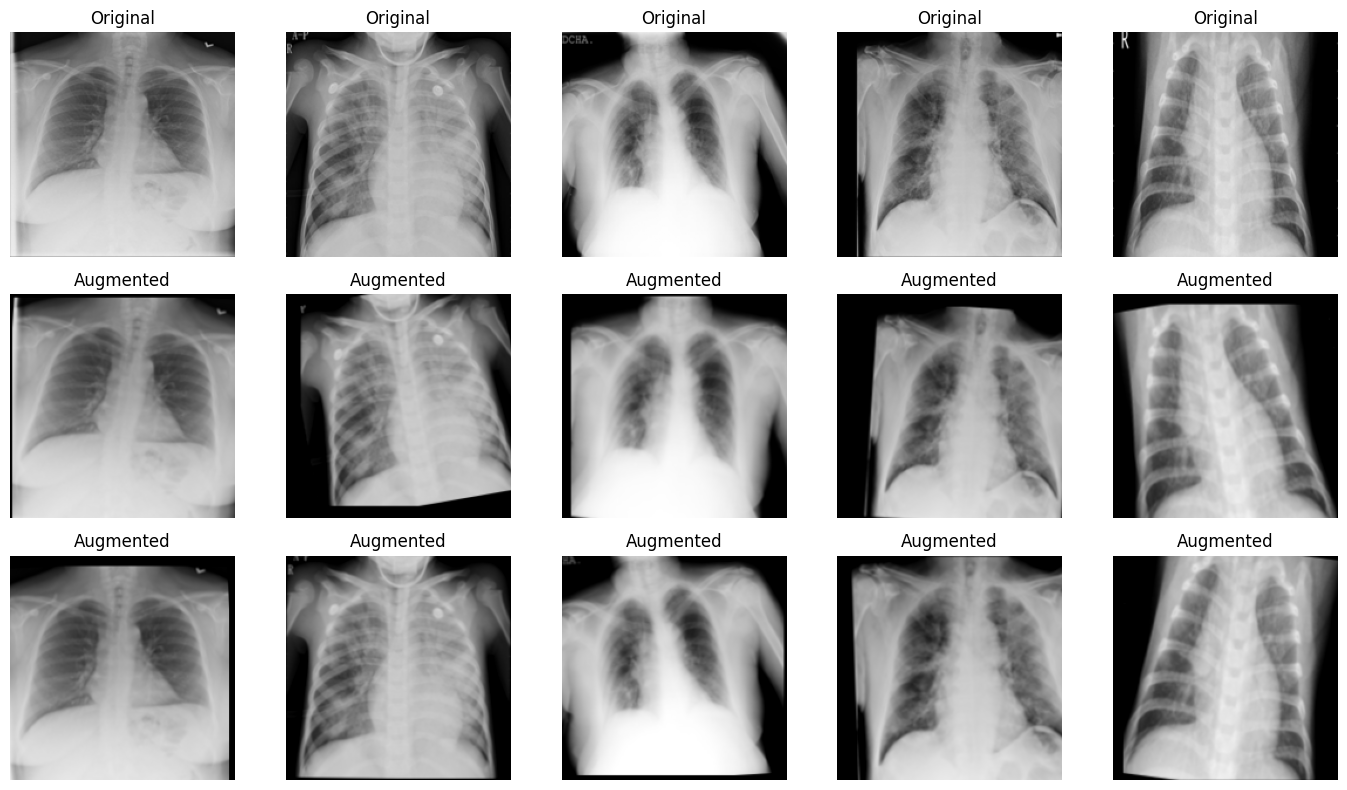

Epoch 1/40
81/81 - 40s - 492ms/step - accuracy: 0.6445 - loss: 0.7947 - val_accuracy: 0.3344 - val_loss: 1.8388 - learning_rate: 0.0010
Epoch 2/40
81/81 - 17s - 213ms/step - accuracy: 0.7111 - loss: 0.6314 - val_accuracy: 0.3328 - val_loss: 5.9176 - learning_rate: 0.0010
Epoch 3/40

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 - 17s - 210ms/step - accuracy: 0.7560 - loss: 0.5601 - val_accuracy: 0.3344 - val_loss: 3.0703 - learning_rate: 0.0010
Epoch 4/40
81/81 - 17s - 212ms/step - accuracy: 0.7909 - loss: 0.4795 - val_accuracy: 0.3607 - val_loss: 1.6385 - learning_rate: 5.0000e-04
Epoch 5/40
81/81 - 18s - 218ms/step - accuracy: 0.8087 - loss: 0.4404 - val_accuracy: 0.5108 - val_loss: 0.9552 - learning_rate: 5.0000e-04
Epoch 6/40
81/81 - 17s - 214ms/step - accuracy: 0.8230 - loss: 0.4101 - val_accuracy: 0.5155 - val_loss: 1.1048 - learning_rate: 5.0000e-04
Epoch 7/40
81/81 - 17s - 213ms/step - accuracy: 0.8222 - loss: 0.4136 - val_accuracy: 0.7074 - 

,Train acc,Train macro-F1,Val acc,Val macro-F1,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Params (M)
Deeper CNN + augmentation,0.9458,0.9454,0.9427,0.9425,0.9281,0.9279,0.1817,0.9405,0.8662,0.9777,1.2084


              precision    recall  f1-score   support

       COVID      0.882     0.941     0.910       269
      NORMAL      0.940     0.866     0.901       269
   PNEUMONIA      0.967     0.978     0.972       269

    accuracy                          0.928       807
   macro avg      0.929     0.928     0.928       807
weighted avg      0.929     0.928     0.928       807



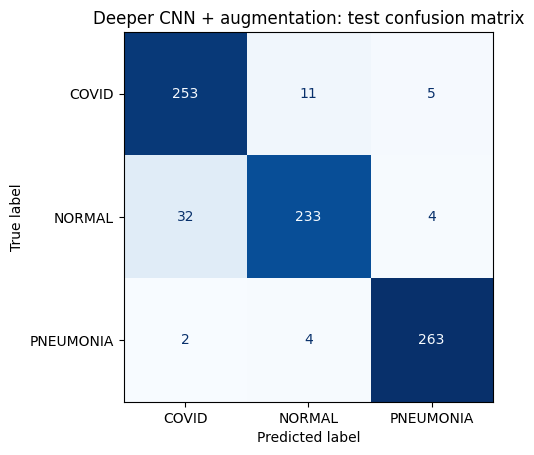

,Train acc,Val acc,Test acc,Test macro-F1,Test loss,Test recall COVID,Test recall NORMAL,Test recall PNEUMONIA,Train − Test acc (overfitting gap)
Deeper CNN,0.9965,0.9567,0.9616,0.9617,0.1221,0.9442,0.9665,0.9740,0.0349
Deeper CNN + augmentation,0.9458,0.9427,0.9281,0.9279,0.1817,0.9405,0.8662,0.9777,0.0176
Difference,-0.0507,-0.0139,-0.0335,-0.0338,0.0595,-0.0037,-0.1004,0.0037,-0.0173


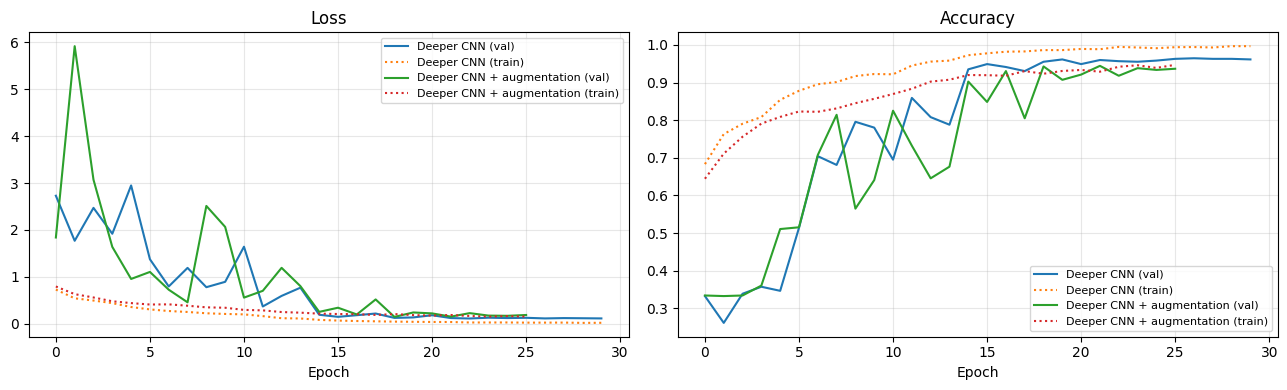

In [ ]:
# Augmentations that keep X-rays anatomically plausible.
# No horizontal/vertical flips: the heart is on the left side, and flipped chest X-rays do not occur in practice.
data_augmentation = Sequential([
    layers.RandomRotation(0.03, fill_mode='constant'),               # up to about ±11°
    layers.RandomZoom(0.1, fill_mode='constant'),                    # zoom in/out up to 10%
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant'),      # shift up to 5% in each direction
    layers.RandomContrast(0.15),                                     # exposure / contrast differences
], name='augmentation')

# Show what the augmented images look like (training=True turns augmentation on)
sample = X_train[:5]
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for j in range(5):
    axes[0, j].imshow(sample[j]); axes[0, j].set_title('Original'); axes[0, j].axis('off')
for r in (1, 2):
    aug = np.clip(np.asarray(data_augmentation(sample, training=True)), 0, 1)
    for j in range(5):
        axes[r, j].imshow(aug[j]); axes[r, j].set_title('Augmented'); axes[r, j].axis('off')
plt.tight_layout()
plt.show()

# Re-train the Deeper CNN (Additional Model 1) with the augmentation layers in front, same settings otherwise
deep_cnn_aug = build_deep_cnn(augmentation=data_augmentation, name='deeper_cnn_augmented')
deep_cnn_aug_history = deep_cnn_aug.fit(
    X_train, y_train_arr,
    validation_data=(X_val, y_val_arr),
    epochs=40, batch_size=BATCH_SIZE,
    callbacks=get_callbacks(patience=7),
    verbose=2)
histories['Deeper CNN + augmentation'] = deep_cnn_aug_history.history

evaluate_model(deep_cnn_aug, 'Deeper CNN + augmentation')

# Compare with and without augmentation
aug_cols = ['Train acc', 'Val acc', 'Test acc', 'Test macro-F1', 'Test loss',
            'Test recall COVID', 'Test recall NORMAL', 'Test recall PNEUMONIA']
aug_table = pd.DataFrame(results).T.loc[['Deeper CNN', 'Deeper CNN + augmentation'], aug_cols]
aug_table.loc['Difference'] = aug_table.iloc[1] - aug_table.iloc[0]
aug_table['Train − Test acc (overfitting gap)'] = aug_table['Train acc'] - aug_table['Test acc']
display(aug_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in ['Deeper CNN', 'Deeper CNN + augmentation']:
    h = histories[name]
    axes[0].plot(h['val_loss'], label=f'{name} (val)')
    axes[0].plot(h['loss'], ls=':', label=f'{name} (train)')
    axes[1].plot(h['val_accuracy'], label=f'{name} (val)')
    axes[1].plot(h['accuracy'], ls=':', label=f'{name} (train)')
axes[0].set_title('Loss'); axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Describe the augmentations you used and why you chose them. How did they affect performance?

We re-trained the deeper CNN (Model 1) with augmentation layers added at the start and everything else unchanged. We picked this model because it is trained from scratch on only 2,582 images, so it seemed the most likely to overfit and to benefit from more varied data.

We tried to only use changes that could realistically happen with a real X-ray: small rotations (up to about ±11°) and small shifts (up to 5%) because patients are never positioned exactly the same, zoom (±10%) since the distance to the detector and patient size vary (and the data has both adults and kids), and contrast changes (±15%) because exposure settings differ between machines. We did not use flips, because a horizontally flipped chest X-ray puts the heart on the wrong side, and vertical flips never happen in practice. These layers are only active during training, so validation and test images are not changed.

The result was not what we expected. Augmentation reduced overfitting but made test performance worse:

| | Train acc | Val acc | Test acc | Macro-F1 | Normal recall |
|---|---|---|---|---|---|
| Deeper CNN | 99.7% | 95.7% | 96.2% | 0.962 | 96.7% |
| + augmentation | 94.6% | 94.3% | 92.8% | 0.928 | 86.6% |

The gap between train and test accuracy went from 3.5 to 1.8 points, so the model memorized the training set less. But test accuracy dropped by 3.4 points, and almost all of that came from normal recall (96.7% to 86.6%). COVID and viral pneumonia recall barely changed (94.4% to 94.1%, and 97.4% to 97.8%), so the augmented model mostly got worse at recognizing healthy lungs.

We think there are a few reasons. First, the model probably didn't train long enough. With augmentation the task is harder, and training accuracy was still going up (about 0.92 to 0.95) when early stopping ended training at epoch 26 (best weights from epoch 19). Its validation loss was also very noisy in the last 10 epochs, jumping between 0.15 and 0.52, which made early stopping kick in early. More epochs, more patience or a lower learning rate would likely help. Second, some of the augmentations might work against what the model needs. From Section 1, normal images differ from COVID mainly by being darker and higher contrast, and random contrast changes or zooming can make a normal lung look hazier. Milder contrast changes might be better. Third, our test set comes from the same sources as the training data, so it can't really show the main benefit of augmentation, which is being more robust to positioning and exposure differences between hospitals.

---

## 7. Interpretability and Insights

Conclude your project:

- **Which model performed best, and why?** Support your reasoning with performance metrics and training curves.
- **What is the practical utility of your best-performing model?**
  - Who would benefit from using this model?
  - In what types of real-world scenarios would your solution be useful?

### Which model performed best, and why?

The best model on the test set was the fine-tuned **VGG19**, with 97.3% accuracy, a macro-F1 of 0.973 and the lowest test loss (0.066, about 40% lower than the next best). It also had the highest recall for COVID (95.9%) and normal (97.8%). For viral pneumonia it got 98.1%, a bit below ResNet50 and DenseNet121 (both 98.9%).

| Rank | Model | Test acc | Macro-F1 | Test loss | Params |
|---|---|---|---|---|---|
| 1 | **VGG19 (fine-tuned)** | **97.3%** | **0.973** | **0.066** | 20.2M |
| 2 | Deeper CNN (scratch) | 96.2% | 0.962 | 0.122 | 1.2M |
| 3 | ResNet50 (fine-tuned) | 95.5% | 0.955 | 0.115 | 24.1M |
| 4 | DenseNet121 (fine-tuned) | 94.8% | 0.948 | 0.134 | 7.3M |
| 5 | Baseline CNN | 91.0% | 0.909 | 0.224 | 2.6M |

The training curves explain most of VGG19's advantage. With the backbone frozen it was actually behind ResNet50 (around 93–94% validation accuracy after 15 epochs vs. about 95%). But once we unfroze block5, validation accuracy jumped to 95.5% in the first fine-tuning epoch and kept improving to 97.7%, while validation loss went from about 0.17 down to 0.09. It stayed stable for all 15 fine-tuning epochs. ResNet50, on the other hand, hit its best validation loss after one fine-tuning epoch and then started overfitting, so it only gained about 0.6 points from fine-tuning.

We think VGG19's simpler structure helps here. The unfrozen block5 is just plain 3×3 convs with no batch norm (about 9.6M parameters), so all of it can adapt to the X-rays. In ResNet50 and DenseNet121 we kept the batch norm layers frozen, which may limit how much they can adjust. Since this task depends a lot on texture and brightness patterns, the extra depth and skip connections may not matter as much. VGG19's much lower test loss also means its probabilities are more reliable, not just its final predictions, which would matter if you set a threshold for flagging cases. Even though it reached 100% training accuracy, its validation (97.2%) and test (97.3%) accuracy are very close, so it doesn't look like a lucky split. Like the other models, most of its mistakes were COVID images predicted as normal.

A few other things stood out. The deeper CNN trained from scratch, with only 1.2M parameters, beat both ResNet50 and DenseNet121, so transfer learning isn't automatically better. Batch norm and global average pooling made a big difference compared to the baseline (96.2% vs 91.0% with half the parameters), although its validation accuracy was really unstable at the start (as low as 26–36% in the first few epochs). DenseNet121 was probably held back because we only unfroze about 1.5M of its parameters, and its validation loss was still slowly going down when training ended (0.178 to 0.135), so more layers or more epochs would likely help. And as discussed in Section 6, augmentation reduced overfitting but lowered test accuracy (96.2% to 92.8%).

### Practical utility of the best model

The most realistic use would be triage. In a busy hospital or ER, the model could sort incoming X-rays so the ones that look like COVID or pneumonia get read first. With 96–98% recall for those two classes on our test set, not many sick patients would end up at the back of the queue. It could also give clinics without an on-site radiologist (for example in rural or low-resource areas) a quick preliminary result while they wait for a specialist, and during an outbreak it could help flag patients for isolation before PCR results come back. It could also work as a second reader that points out images a radiologist might have marked as normal.

There are important limitations though. About 4% of COVID X-rays in our test set were missed, mostly predicted as normal, which is the worst kind of mistake for screening, so in practice the threshold should be adjusted to catch more COVID cases even if that means more false alarms. Our training and test images come from the same public collection, where the source is partly linked to the class, so some of the accuracy may come from dataset shortcuts. The model also only knows three classes and was trained on balanced data, which isn't what real patient populations look like. Before any real use it would need testing on X-rays from other hospitals, something like Grad-CAM to show what the model is looking at, regulatory approval, and a doctor always making the final decision.